# 5 - Where the models fail

Error analysis of the ten runs of notebooks 01-04. It reads their saved predictions
(`results/<run>/*_predictions.csv`), the raw images and, for section 5 only, their checkpoints in `models/`.
Tables and figures go to `results/analysis/`; the write-up is `REPORT.md`.

"Strong models" are the nine runs other than the basic NN.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from matplotlib.patches import Rectangle
from PIL import Image
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.metrics import f1_score

import config
from src import data, experiment
from src.compare import macro_f1

experiment.setup()
OUT = config.RESULTS_DIR / "analysis"
OUT.mkdir(parents=True, exist_ok=True)
frames = data.load_frames()
images = pd.concat(frames.values(), ignore_index=True)
board = pd.read_csv(config.RESULTS_DIR / "leaderboard.csv")
RUNS = board.run.tolist()
STRONG = [run for run in RUNS if run != "basic_nn"]
predictions = {(run, split): pd.read_csv(config.RESULTS_DIR / run / f"{split}_predictions.csv")
               for run in RUNS for split in ("val", "test")}

# Chart style: validated 3-slot categorical palette, recessive grid, ink-coloured text.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
                     "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False})


def show_images(rows, titles, path, suptitle, cols=8, crop_box=False):
    """Grid of raw images; crop_box draws the center square crop the models see."""
    grid_rows = max(1, int(np.ceil(len(rows) / cols)))
    fig, axes = plt.subplots(grid_rows, cols, figsize=(2.6 * cols, 2.3 * grid_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, filepath, title in zip(axes.flat, rows, titles):
        image = Image.open(config.DATASET_ROOT / filepath).convert("RGB")
        ax.imshow(image)
        if crop_box:
            w, h = image.size
            side = min(w, h)
            ax.add_patch(Rectangle(((w - side) / 2, (h - side) / 2), side, side, fill=False, ec="#2a78d6", lw=2))
        ax.set_title(title, fontsize=8)
    fig.suptitle(suptitle)
    fig.tight_layout()
    fig.savefig(path, dpi=70)
    plt.show()

I0000 00:00:1791596287.950228  142741 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791596287.996218  142741 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791596289.159769  142741 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | policy: float32


## 1. The strong models make the same test errors

For every image, count how many of the nine strong models get it wrong, and what most of them predict.

In [2]:
consensus = {}
for split in ("val", "test"):
    frame = predictions[(STRONG[0], split)][["filepath", "label", "aspect_group"]].copy()
    predicted = np.stack([predictions[(run, split)].predicted.to_numpy() for run in STRONG], 1)
    frame["n_wrong"] = (predicted != frame.label.to_numpy()[:, None]).sum(1)
    frame["majority"] = pd.DataFrame(predicted).mode(axis=1)[0]
    consensus[split] = frame
    print(f"{split}: wrong in all 9 = {(frame.n_wrong == 9).sum()}, in >= 7 = {(frame.n_wrong >= 7).sum()}, "
          f"in none = {(frame.n_wrong == 0).sum()} (of {len(frame)})")
shared = consensus["test"][consensus["test"].n_wrong >= 7]
pd.crosstab(shared.label, shared.majority).rename_axis(index="test label", columns="majority prediction (>= 7 of 9 wrong)")

val: wrong in all 9 = 2, in >= 7 = 9, in none = 646 (of 800)
test: wrong in all 9 = 94, in >= 7 = 141, in none = 469 (of 800)


majority prediction (>= 7 of 9 wrong),fire,nofire,smoke,smokefire
test label,,,,
fire,0,2,1,60
nofire,1,0,1,0
smoke,0,1,0,52
smokefire,0,0,23,0


## 2. Validation is mostly augmented copies of training images

The Kaggle images were produced by augmenting source photos (rotations, flips, shifts whose empty borders
are filled by stretching the edge pixels). If copies of one photo sit in both train and validation, the
validation score measures recall of seen photos, not generalisation. Test: embed every image with a plain
ImageNet ResNet-50 (center crop, no fine-tuning), find each val/test image's most similar training image,
and classify it with that neighbour's label (1-NN, no training at all). A difference hash (dHash) of the
full image catches byte-level near-duplicates, which it turns out are rare: the copies are rotated or
shifted.

In [3]:
backbone, preprocess = experiment.backbone("resnet50")
inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
embedder = keras.Model(inputs, backbone(preprocess(inputs), training=False))
embeddings = embedder.predict(data.make_dataset(images).map(lambda x, y: x), verbose=0)
embeddings /= np.linalg.norm(embeddings, axis=1, keepdims=True)


def dhash(filepath):
    pixels = np.asarray(Image.open(config.DATASET_ROOT / filepath).convert("L").resize((9, 8), Image.Resampling.LANCZOS),
                        dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()


hashes = np.stack([dhash(p) for p in images.filepath])
train = (images.split == "train").to_numpy()
train_index = np.flatnonzero(train)
rows = []
for split in ("val", "test"):
    query = (images.split == split).to_numpy()
    similarity = embeddings[query] @ embeddings[train].T
    nearest = similarity.argmax(1)
    images.loc[query, "nn_cos"] = similarity.max(1)
    images.loc[query, "nn_train_row"] = train_index[nearest]
    images.loc[query, "nn_label"] = images.label.to_numpy()[train_index[nearest]]
    images.loc[query, "nn_hamming"] = (hashes[query][:, None, :] != hashes[train][None, :, :]).sum(2).min(1)
    part = images[query]
    for label, group in [("all", part), *part.groupby("label")]:
        rows.append({"split": split, "label": label, "n": len(group), "median cosine to nearest train": group.nn_cos.median(),
                     "share cosine > 0.9": (group.nn_cos > 0.9).mean(), "share dHash <= 6 bits": (group.nn_hamming <= 6).mean(),
                     "1-NN accuracy": (group.nn_label == group.label).mean()})
neighbours = pd.DataFrame(rows)
neighbours.to_csv(OUT / "nearest_train_neighbour.csv", index=False, float_format="%.4f")
neighbours.round(3)

I0000 00:00:1791596291.217083  142741 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3618 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


I0000 00:00:1791596294.822828  142808 service.cc:153] XLA service 0x7e7cb4075bb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791596294.822866  142808 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1791596294.880655  142808 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1791596295.359124  142808 cuda_dnn.cc:461] Loaded cuDNN version 92000


I0000 00:00:1791596300.004423  142808 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,split,label,n,median cosine to nearest train,share cosine > 0.9,share dHash <= 6 bits,1-NN accuracy
0,val,all,800,0.855,0.206,0.002,0.970
1,val,fire,200,0.856,0.245,0.000,0.955
2,val,nofire,200,0.819,0.095,0.000,0.975
3,val,smoke,200,0.878,0.310,0.005,1.000
4,val,smokefire,200,0.855,0.175,0.005,0.950
5,test,all,800,0.814,0.085,0.004,0.745
6,test,fire,200,0.806,0.020,0.005,0.625
7,test,nofire,200,0.724,0.015,0.000,0.890
8,test,smoke,200,0.842,0.165,0.005,0.680
9,test,smokefire,200,0.851,0.140,0.005,0.785


Val images and their nearest training image, sampled across the similarity range (10th to 97th percentile):

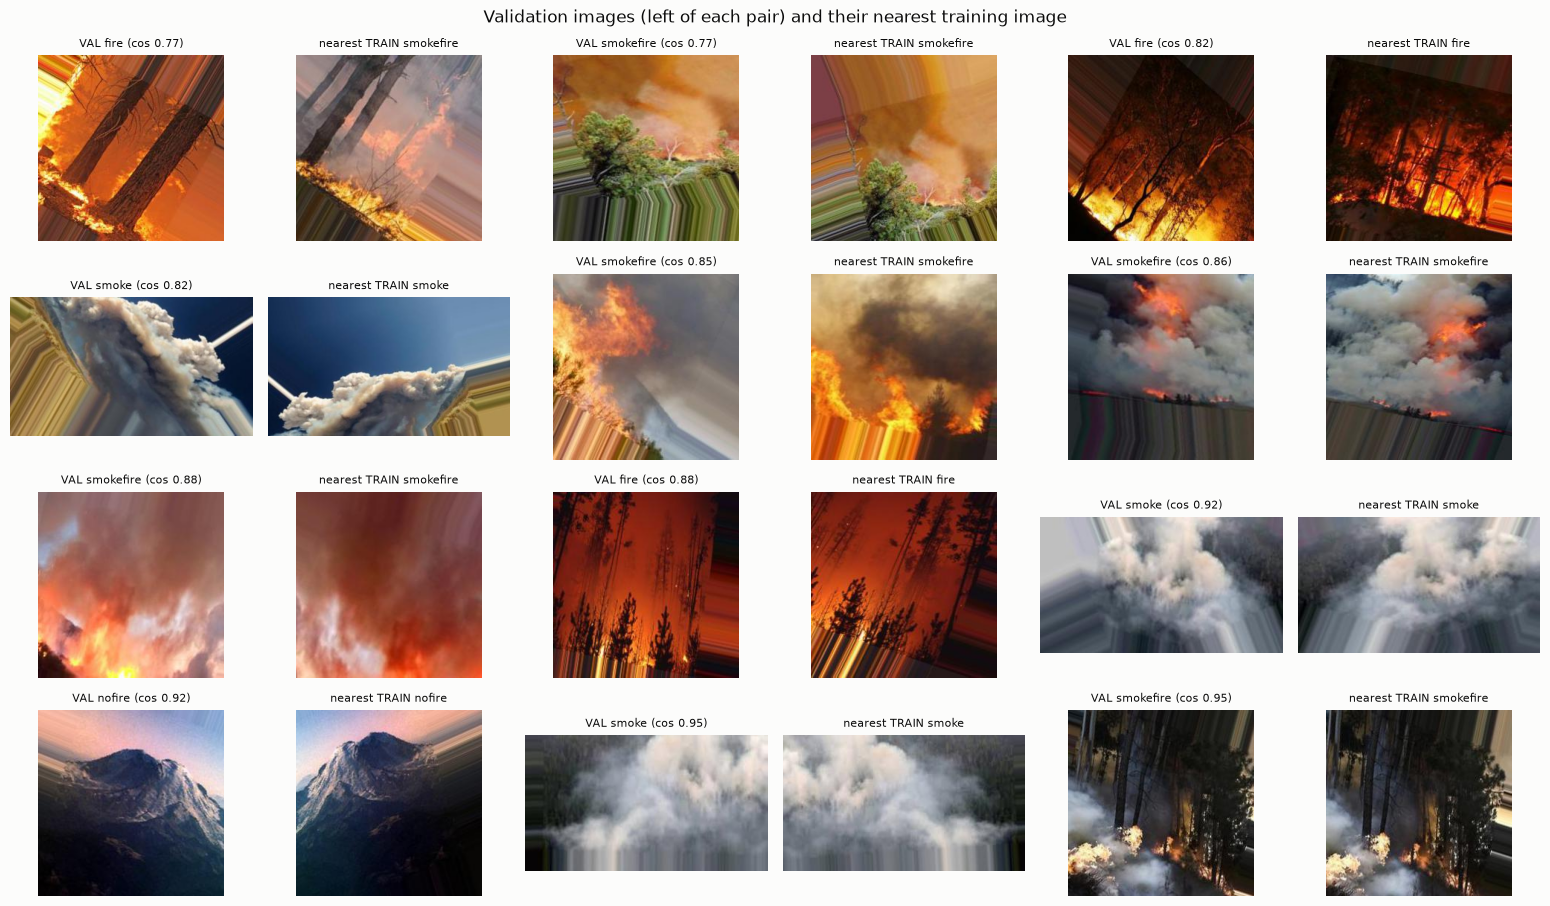

In [4]:
val = images[images.split == "val"]
picked = pd.concat([val.iloc[(val.nn_cos - q).abs().argsort().iloc[:2]] for q in val.nn_cos.quantile([0.1, 0.3, 0.5, 0.7, 0.9, 0.97])])
paths, titles = [], []
for row in picked.itertuples():
    paths += [row.filepath, images.filepath[int(row.nn_train_row)]]
    titles += [f"VAL {row.label} (cos {row.nn_cos:.2f})", f"nearest TRAIN {row.nn_label}"]
show_images(paths, titles, OUT / "val_train_pairs.png", "Validation images (left of each pair) and their nearest training image", cols=6)

Accuracy against similarity to the nearest training image:

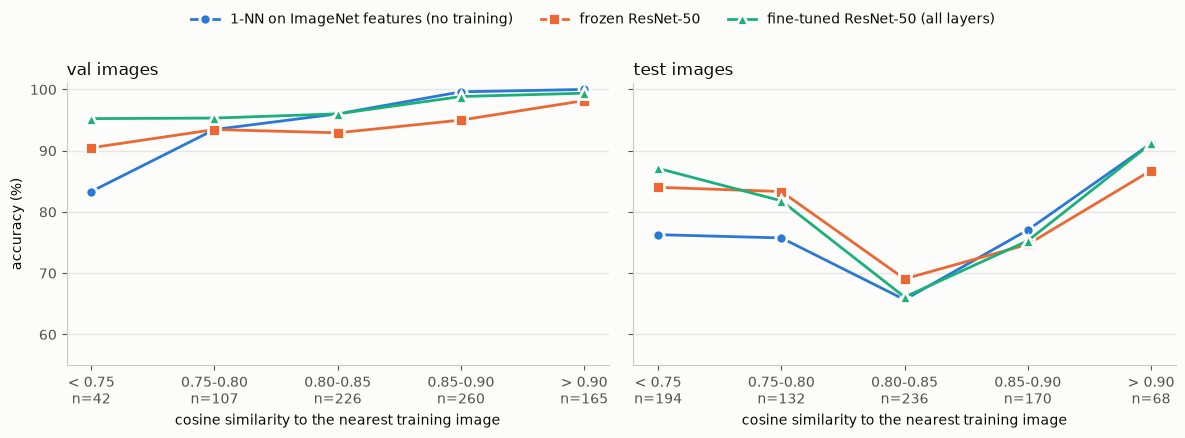

n  1-NN on ImageNet features (no training)  \
split nn_cos                                                    
val   < 0.75      42                                     83.3   
      0.75-0.80  107                                     93.5   
      0.80-0.85  226                                     96.0   
      0.85-0.90  260                                     99.6   
      > 0.90     165                                    100.0   
test  < 0.75     194                                     76.3   
      0.75-0.80  132                                     75.8   
      0.80-0.85  236                                     65.7   
      0.85-0.90  170                                     77.1   
      > 0.90      68                                     91.2   

                 frozen ResNet-50  fine-tuned ResNet-50 (all layers)  
split nn_cos                                                          
val   < 0.75                 90.5                               95.2  
      0.75-0.80              93.5                               95.3  
      0.80-0.85              92.9                               96.0  
      0.85-0.90              95.0                               98.8  
      > 0.90                 98.2                               99.4  
test  < 0.75                 84.0                               87.1  
      0.75-0.80              83.3                               81.8  
      0.80-0.85              69.1                               66.1  
      0.85-0.90              74.7                               75.3  
      > 0.90                 86.8                               91.2

In [5]:
bins = [0, 0.75, 0.80, 0.85, 0.90, 1.0]
bin_names = ["< 0.75", "0.75-0.80", "0.80-0.85", "0.85-0.90", "> 0.90"]
series = {"1-NN on ImageNet features (no training)": None, "frozen ResNet-50": "frozen_resnet50",
          "fine-tuned ResNet-50 (all layers)": "ft_all_resnet50"}
by_bin = {}
for split in ("val", "test"):
    part = images[images.split == split].reset_index(drop=True)
    bucket = pd.cut(part.nn_cos, bins, labels=bin_names)
    table = {"n": part.groupby(bucket, observed=False).size()}
    for name, run in series.items():
        correct = (part.nn_label == part.label) if run is None else (predictions[(run, split)].predicted == part.label)
        table[name] = correct.groupby(bucket, observed=False).mean() * 100
    by_bin[split] = pd.DataFrame(table)
pd.concat(by_bin, names=["split"]).round(1).to_csv(OUT / "accuracy_by_similarity.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, split in zip(axes, ("val", "test")):
    table = by_bin[split]
    for (name, _), color, marker in zip(series.items(), SERIES, ["o", "s", "^"]):
        ax.plot(range(len(table)), table[name], color=color, lw=2, marker=marker, ms=8, mec="#fcfcfb", mew=2, label=name)
    ax.set_xticks(range(len(table)), [f"{b}\nn={n}" for b, n in zip(bin_names, table.n)])
    ax.set_xlabel("cosine similarity to the nearest training image")
    ax.set_title(f"{split} images", loc="left")
    ax.grid(axis="y", color="#e6e5e1", lw=1)
    ax.set_axisbelow(True)
axes[0].set_ylabel("accuracy (%)")
axes[0].set_ylim(55, 101)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(OUT / "accuracy_vs_similarity.png", dpi=110)
plt.show()
pd.concat(by_bin, names=["split"]).round(1)

## 3. Test smoke and smokefire come from other, fewer source photos

Image sizes per split and class, then how many visually distinct groups each test class collapses to
(average-linkage clustering of the embeddings at cosine distance 0.15 and 0.25).

In [6]:
images["pixels"] = images.width * images.height
images["size"] = images.width.astype(str) + "x" + images.height.astype(str)
sizes = images.groupby(["split", "label"]).agg(median_width=("width", "median"), median_height=("height", "median"),
                                               median_pixels=("pixels", "median"), distinct_sizes=("size", "nunique"))
test = images[images.split == "test"].copy()
groups = {}
for label, part in test.groupby("label"):
    vectors = embeddings[part.index]
    distance = np.clip(1 - vectors @ vectors.T, 0, 2)
    np.fill_diagonal(distance, 0)
    tree = linkage(squareform(distance, checks=False), "average")
    for threshold in (0.15, 0.25):
        test.loc[part.index, f"cluster_{threshold}"] = fcluster(tree, threshold, "distance")
    groups[label] = {"images": len(part), "clusters at 0.15": test.loc[part.index, "cluster_0.15"].nunique(),
                     "clusters at 0.25": test.loc[part.index, "cluster_0.25"].nunique()}
sizes.to_csv(OUT / "image_sizes.csv")
display(sizes.round(0))
pd.DataFrame(groups).T

median_width  median_height  median_pixels  distinct_sizes
split label                                                                
test  fire              250.0          250.0        62500.0               1
      nofire            250.0          250.0        62500.0               1
      smoke             852.0          480.0       408960.0               8
      smokefire         835.0          493.0       381300.0              10
train fire              250.0          250.0        62500.0               1
      nofire            250.0          250.0        62500.0              11
      smoke             299.0          184.0        50400.0              52
      smokefire         250.0          250.0        62500.0              11
val   fire              250.0          250.0        62500.0               1
      nofire            250.0          250.0        62500.0               4
      smoke             299.0          186.0        50400.0              49
      smokefire         250.0          250.0        62500.0               8

,images,clusters at 0.15,clusters at 0.25
fire,200,181,94
nofire,200,187,137
smoke,200,98,31
smokefire,200,42,14


One size group of test `smoke` (62 images at 852x480): a few photos, each rotated, flipped and shifted many times.

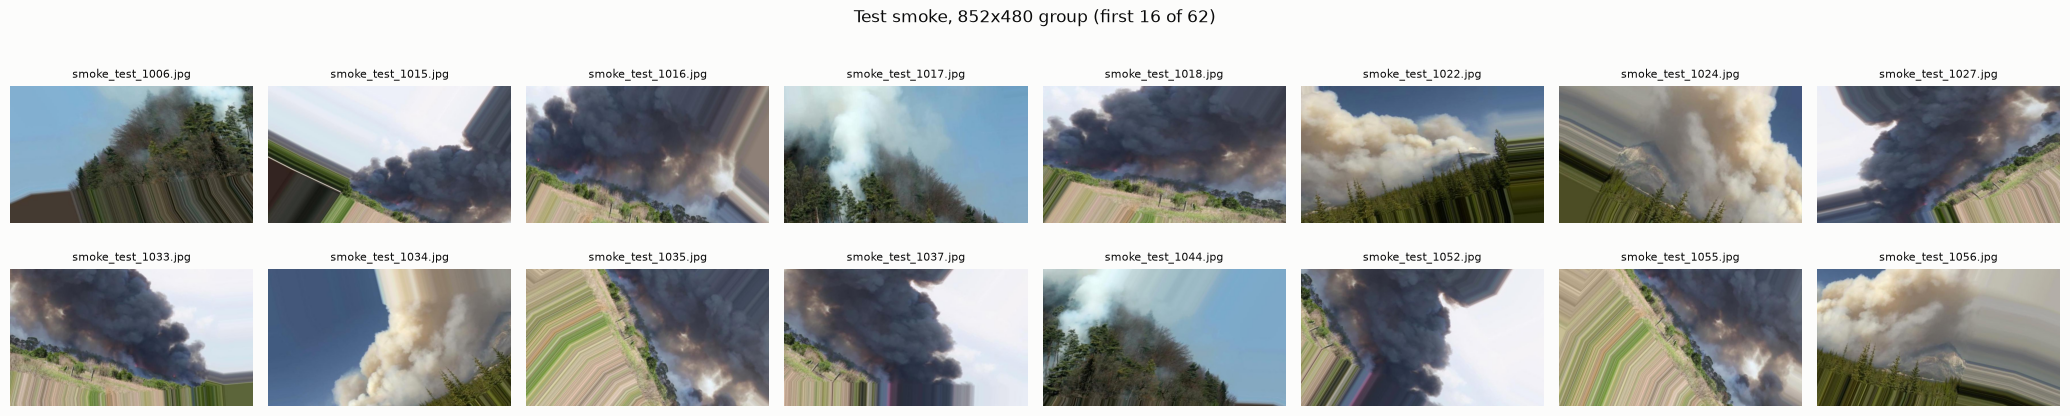

In [7]:
group = test[(test.label == "smoke") & (test.width == 852) & (test.height == 480)].head(16)
show_images(group.filepath, [p.split("/")[-1] for p in group.filepath], OUT / "test_smoke_852x480.png",
            "Test smoke, 852x480 group (first 16 of 62)")

## 4. What the shared test errors look like

Test images that all nine strong models get wrong, per (label, prediction). The blue square is the center
crop the models see.

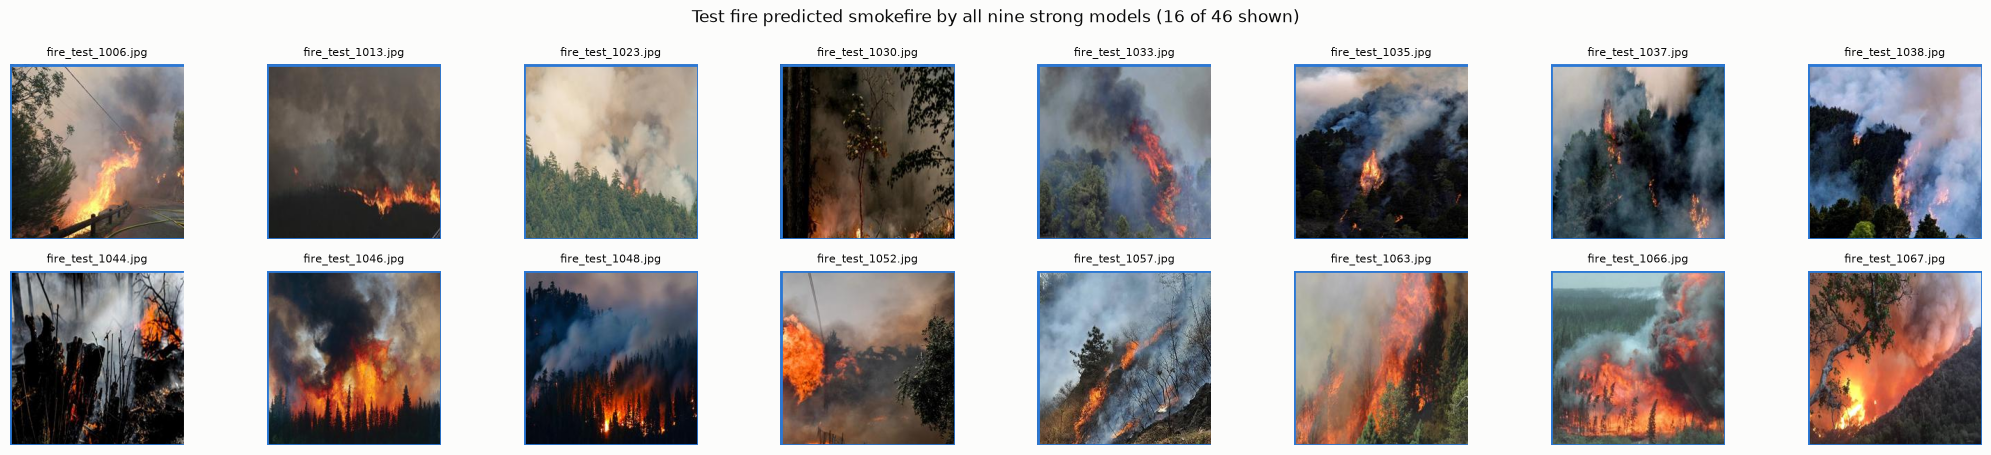

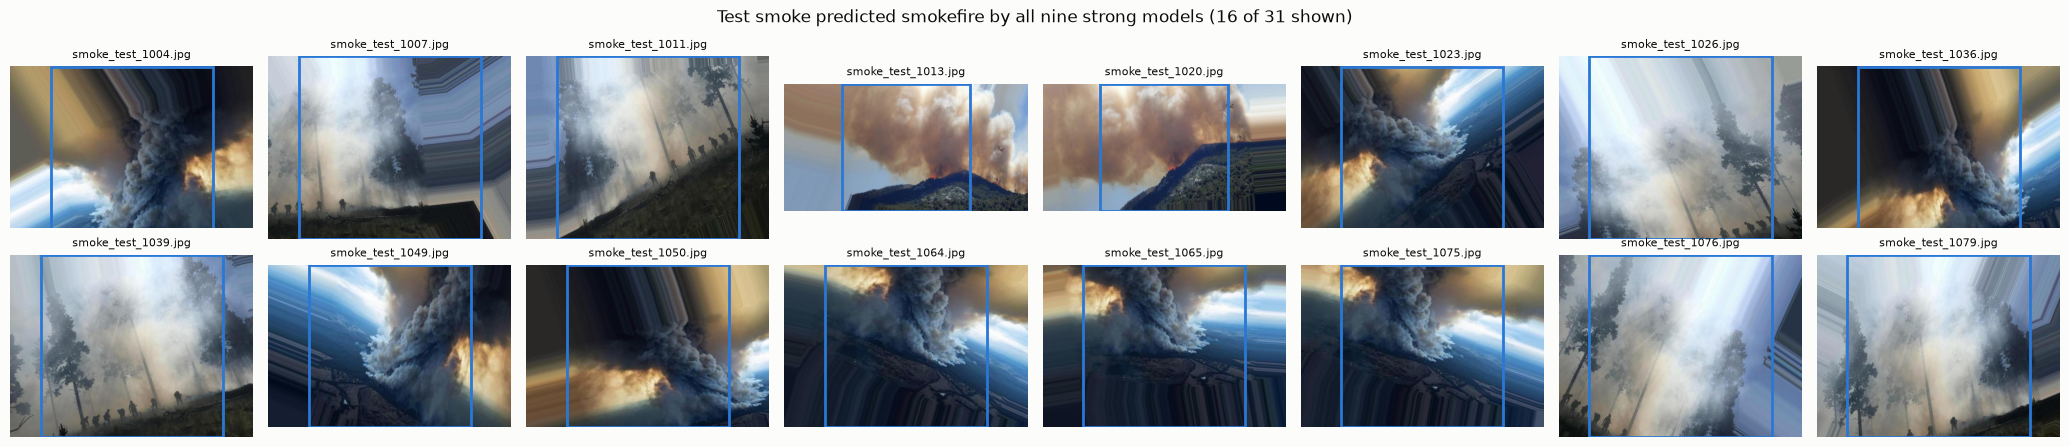

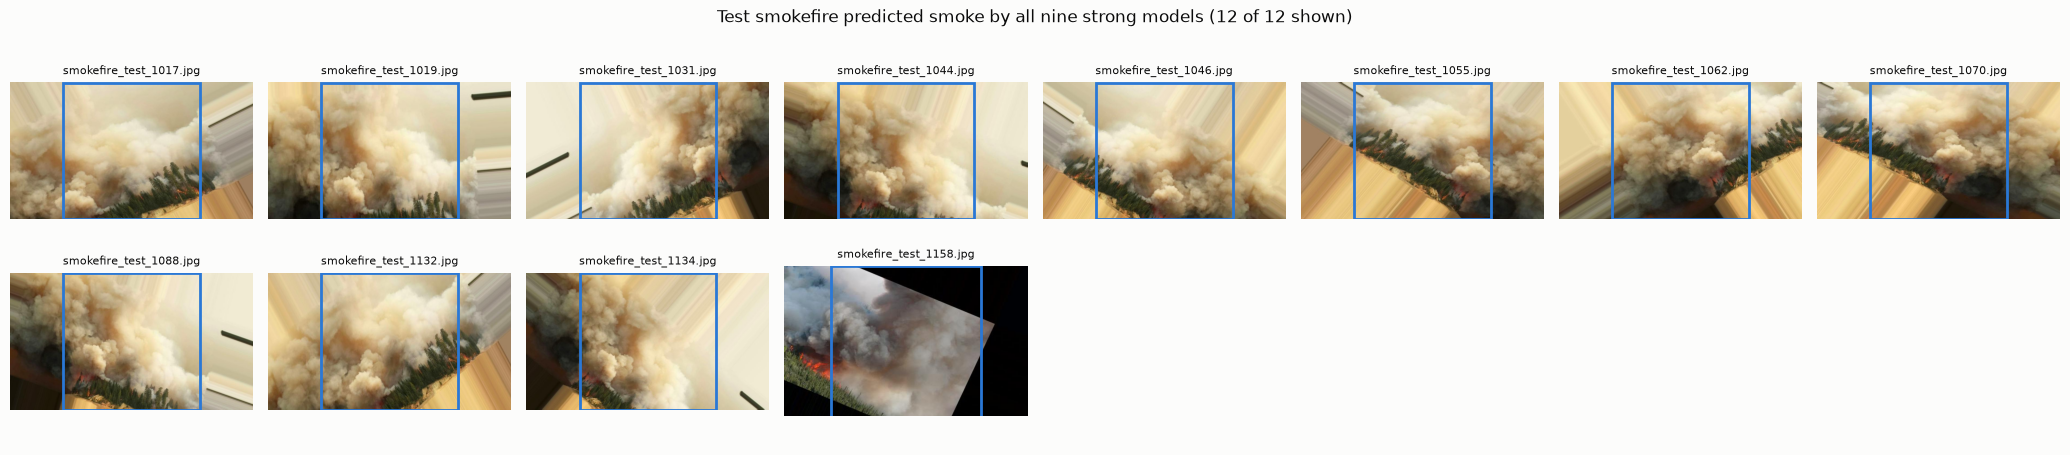

In [8]:
shared_all = consensus["test"][consensus["test"].n_wrong == 9]
for (label, majority), part in shared_all.groupby(["label", "majority"]):
    if len(part) < 5:
        continue
    shown = part.head(16)
    show_images(shown.filepath, [p.split("/")[-1] for p in shown.filepath], OUT / f"shared_errors_{label}_as_{majority}.png",
                f"Test {label} predicted {majority} by all nine strong models ({len(shown)} of {len(part)} shown)",
                crop_box=True)

## 5. Does the center crop cut the fire away?

Re-score three checkpoints with the mean prediction of three square crops (left/top, center,
right/bottom) instead of the center crop alone. Square images give three identical crops, so only the wide
and other-shaped images can change. The model builders repeat those of notebooks 03 and 04.

In [9]:
def build_frozen(name):   # notebook 03
    base, preprocess = experiment.backbone(name)
    inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
    x = base(preprocess(inputs), training=False)
    x = layers.Dropout(0.45)(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.BatchNormalization(momentum=0.9, epsilon=1e-5)(x)
    x = layers.Dropout(0.2)(x)
    return keras.Model(inputs, layers.Dense(len(config.CLASS_NAMES), activation="softmax")(x))


def build_motif(name):   # notebook 04
    base, preprocess = experiment.backbone(name)
    inputs = keras.Input((config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
    x = base(preprocess(inputs), training=False)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    return keras.Model(inputs, layers.Dense(len(config.CLASS_NAMES), activation="softmax", dtype="float32")(x))


def square_crops(frame, position):
    """position 0 = left/top, 0.5 = center (what the models were evaluated on), 1 = right/bottom."""
    columns = (frame.path.to_numpy(), frame.height.to_numpy("int32"), frame.width.to_numpy("int32"))

    def load(path, height, width):
        side = tf.minimum(height, width)
        top = tf.cast(tf.cast(height - side, tf.float32) * position, tf.int32)
        left = tf.cast(tf.cast(width - side, tf.float32) * position, tf.int32)
        image = tf.io.decode_and_crop_jpeg(tf.io.read_file(path), tf.stack([top, left, side, side]), channels=3)
        return tf.image.resize(image, [config.IMAGE_SIZE, config.IMAGE_SIZE], antialias=True)

    return tf.data.Dataset.from_tensor_slices(columns).map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(config.BATCH_SIZE)


rows = []
for run, build in [("frozen_resnet50", lambda: build_frozen("resnet50")), ("ft_all_resnet50", lambda: build_motif("resnet50")),
                   ("ft_all_xception", lambda: build_motif("xception"))]:
    keras.backend.clear_session()
    model = build()
    model.load_weights(config.MODELS_DIR / f"{run}.weights.h5")
    for split in ("val", "test"):
        frame = frames[split]
        truth = frame.class_index.to_numpy()
        crops = {position: model.predict(square_crops(frame, position), verbose=0) for position in (0.0, 0.5, 1.0)}
        saved = predictions[(run, split)].predicted.map(config.CLASS_TO_INDEX).to_numpy()
        not_square = (frame.aspect_group != "square").to_numpy()
        for name, probabilities in [("center crop (as evaluated)", crops[0.5]), ("mean of 3 crops", sum(crops.values()) / 3)]:
            predicted = probabilities.argmax(1)
            rows.append({"run": run, "split": split, "evaluation": name,
                         "macro F1": f1_score(truth, predicted, average="macro") * 100,
                         "accuracy, non-square images": (predicted == truth)[not_square].mean() * 100,
                         "agrees with saved predictions": (crops[0.5].argmax(1) == saved).mean() * 100})
crop_check = pd.DataFrame(rows)
crop_check.to_csv(OUT / "three_crop_check.csv", index=False, float_format="%.2f")
crop_check.round(2)

E0000 00:00:1791596370.500044  142808 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1791596373.182883  142808 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1791596379.341938  142808 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1791596380.832275  142808 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


,run,split,evaluation,macro F1,"accuracy, non-square images",agrees with saved predictions
0,frozen_resnet50,val,center crop (as evaluated),94.63,98.06,100.0
1,frozen_resnet50,val,mean of 3 crops,94.62,98.06,100.0
2,frozen_resnet50,test,center crop (as evaluated),78.40,74.50,100.0
3,frozen_resnet50,test,mean of 3 crops,78.09,74.00,100.0
4,ft_all_resnet50,val,center crop (as evaluated),97.50,99.51,100.0
5,ft_all_resnet50,val,mean of 3 crops,97.50,99.51,100.0
6,ft_all_resnet50,test,center crop (as evaluated),78.58,74.00,100.0
7,ft_all_resnet50,test,mean of 3 crops,78.46,73.75,100.0
8,ft_all_xception,val,center crop (as evaluated),96.88,98.54,100.0
9,ft_all_xception,val,mean of 3 crops,97.01,99.03,100.0


## 6. Confidence of the wrong predictions

In [10]:
rows = []
for run in ["custom_cnn", "frozen_xception", "frozen_resnet50", "ft_all_xception", "ft_all_resnet50"]:
    for split in ("val", "test"):
        p = predictions[(run, split)]
        wrong = p[p.label != p.predicted]
        rows.append({"run": run, "split": split, "errors": len(wrong),
                     "median confidence, errors": wrong.confidence.median(),
                     "share of errors above 0.9": (wrong.confidence > 0.9).mean(),
                     "median confidence, correct": p[p.label == p.predicted].confidence.median()})
confidence = pd.DataFrame(rows)
confidence.to_csv(OUT / "error_confidence.csv", index=False, float_format="%.3f")
confidence.round(3)

,run,split,errors,"median confidence, errors",share of errors above 0.9,"median confidence, correct"
0,custom_cnn,val,35,0.734,0.229,0.957
1,custom_cnn,test,190,0.920,0.547,0.964
2,frozen_xception,val,81,0.697,0.123,0.963
3,frozen_xception,test,209,0.767,0.306,0.927
4,frozen_resnet50,val,43,0.785,0.279,0.998
5,frozen_resnet50,test,178,0.959,0.624,0.996
6,ft_all_xception,val,25,0.846,0.320,1.000
7,ft_all_xception,test,179,0.997,0.821,1.000
8,ft_all_resnet50,val,20,0.794,0.350,1.000
9,ft_all_resnet50,test,177,0.996,0.780,1.000


## 7. Does validation rank the models, and how wide is test uncertainty really?

Spearman rank correlation between validation and test macro F1 across runs. Then the test bootstrap again,
resampling the clusters of section 3 (within each class) instead of single images, since copies of one
photo are not independent.

In [11]:
strong_board = board[board.val_f1 > 0.93]
print(f"Spearman val vs test macro F1: all {len(board)} runs {spearmanr(board.val_f1, board.test_f1).statistic:.2f}; "
      f"the {len(strong_board)} runs with val F1 > 0.93: {spearmanr(strong_board.val_f1, strong_board.test_f1).statistic:.2f}")

truth = test.label.map(config.CLASS_TO_INDEX).to_numpy()
labels = {run: predictions[(run, "test")].predicted.map(config.CLASS_TO_INDEX).to_numpy() for run in RUNS}
rng = np.random.default_rng(0)
rows = {run: {"test macro F1": macro_f1(truth, labels[run]) * 100} for run in RUNS}
image_level = pd.read_csv(config.RESULTS_DIR / "comparison.csv").query("split == 'test'").set_index("run")
for run in RUNS:
    rows[run]["image bootstrap, F1 95%"] = f"[{100 * image_level.f1_low[run]:.1f}, {100 * image_level.f1_high[run]:.1f}]"
    rows[run]["image bootstrap, vs frozen ResNet-50"] = f"[{100 * image_level.delta_low[run]:+.1f}, {100 * image_level.delta_high[run]:+.1f}]"
for threshold in (0.15, 0.25):
    key = test.label + ":" + test[f"cluster_{threshold}"].astype(int).astype(str)
    members = [np.flatnonzero((key == k).to_numpy()) for k in key.unique()]
    member_label = np.array([test.label.iloc[m[0]] for m in members])
    boot = {run: [] for run in RUNS}
    for _ in range(3000):
        index = np.concatenate([np.concatenate([members[g] for g in rng.choice(np.flatnonzero(member_label == label), (member_label == label).sum())])
                                for label in config.CLASS_NAMES])
        for run in RUNS:
            boot[run].append(macro_f1(truth[index], labels[run][index]))
    reference = np.array(boot["frozen_resnet50"])
    for run in RUNS:
        values = np.array(boot[run]) * 100
        delta = values - reference * 100
        rows[run][f"cluster bootstrap {threshold} ({len(members)} clusters), F1 95%"] = f"[{np.percentile(values, 2.5):.1f}, {np.percentile(values, 97.5):.1f}]"
        rows[run][f"cluster bootstrap {threshold}, vs frozen ResNet-50"] = f"[{np.percentile(delta, 2.5):+.1f}, {np.percentile(delta, 97.5):+.1f}]"
uncertainty = pd.DataFrame(rows).T
uncertainty.to_csv(OUT / "test_uncertainty.csv")
uncertainty.round(1)

Spearman val vs test macro F1: all 10 runs 0.70; the 7 runs with val F1 > 0.93: 0.11


,test macro F1,"image bootstrap, F1 95%","image bootstrap, vs frozen ResNet-50","cluster bootstrap 0.15 (508 clusters), F1 95%","cluster bootstrap 0.15, vs frozen ResNet-50","cluster bootstrap 0.25 (276 clusters), F1 95%","cluster bootstrap 0.25, vs frozen ResNet-50"
basic_nn,60.879076,"[57.5, 64.2]","[-21.2, -13.9]","[55.3, 66.6]","[-23.9, -10.9]","[51.9, 69.0]","[-27.3, -7.6]"
custom_cnn,76.483647,"[73.5, 79.2]","[-4.4, +0.4]","[71.7, 80.7]","[-5.5, +1.1]","[68.8, 83.1]","[-6.2, +2.1]"
frozen_xception,74.616879,"[71.7, 77.4]","[-6.2, -1.4]","[70.6, 78.5]","[-6.3, -1.5]","[68.1, 80.6]","[-6.3, -1.3]"
frozen_resnet50,78.395683,"[75.7, 81.0]","[+0.0, +0.0]","[74.1, 82.4]","[+0.0, +0.0]","[71.0, 85.2]","[+0.0, +0.0]"
ft_stage1_xception,71.954507,"[68.9, 74.9]","[-9.0, -3.9]","[67.4, 76.5]","[-9.5, -3.6]","[64.8, 78.6]","[-10.3, -2.7]"
ft_top_xception,76.596493,"[73.8, 79.3]","[-3.8, +0.2]","[72.1, 80.7]","[-3.9, +0.1]","[69.2, 83.5]","[-4.3, +0.6]"
ft_all_xception,78.280774,"[75.5, 80.9]","[-2.2, +2.0]","[74.0, 82.3]","[-2.9, +2.5]","[71.2, 84.5]","[-3.9, +3.5]"
ft_stage1_resnet50,78.589148,"[75.9, 81.2]","[-1.2, +1.6]","[74.2, 82.6]","[-1.3, +1.6]","[71.2, 85.1]","[-1.6, +2.2]"
ft_top_resnet50,78.124322,"[75.3, 80.7]","[-2.1, +1.5]","[73.3, 82.3]","[-2.8, +2.0]","[70.1, 85.1]","[-3.6, +2.7]"
ft_all_resnet50,78.575246,"[75.8, 81.1]","[-1.6, +1.9]","[73.7, 82.9]","[-2.3, +2.6]","[70.8, 85.8]","[-3.0, +3.3]"
